
===== FIRST 5 ROWS =====
   Gender Age_in_years     University_name Education_Level Resident  \
0    Male          25+  Islamic University          MS/MSc     Mess   
1    Male        19-25  Islamic University        1st Year     Mess   
2    Male        19-25  Islamic University        1st Year     Mess   
3    Male        19-25  Islamic University        1st Year     Mess   
4  Female        19-25  Islamic University        1st Year     Mess   

          Smoking_Status    Family_Type Father_Occupation  \
0  I am a current smoker  Single Family               Job   
1    I have never smoked  Single Family            Others   
2    I have never smoked   Joint Family          Teaching   
3    I have never smoked  Single Family           Farming   
4    I have never smoked  Single Family               Job   

  Father_Education_Level Mother_Occupation  ... Impact_Learning_Ability  \
0       Graduate & above         Housewife  ...               No impact   
1       Graduate & above      

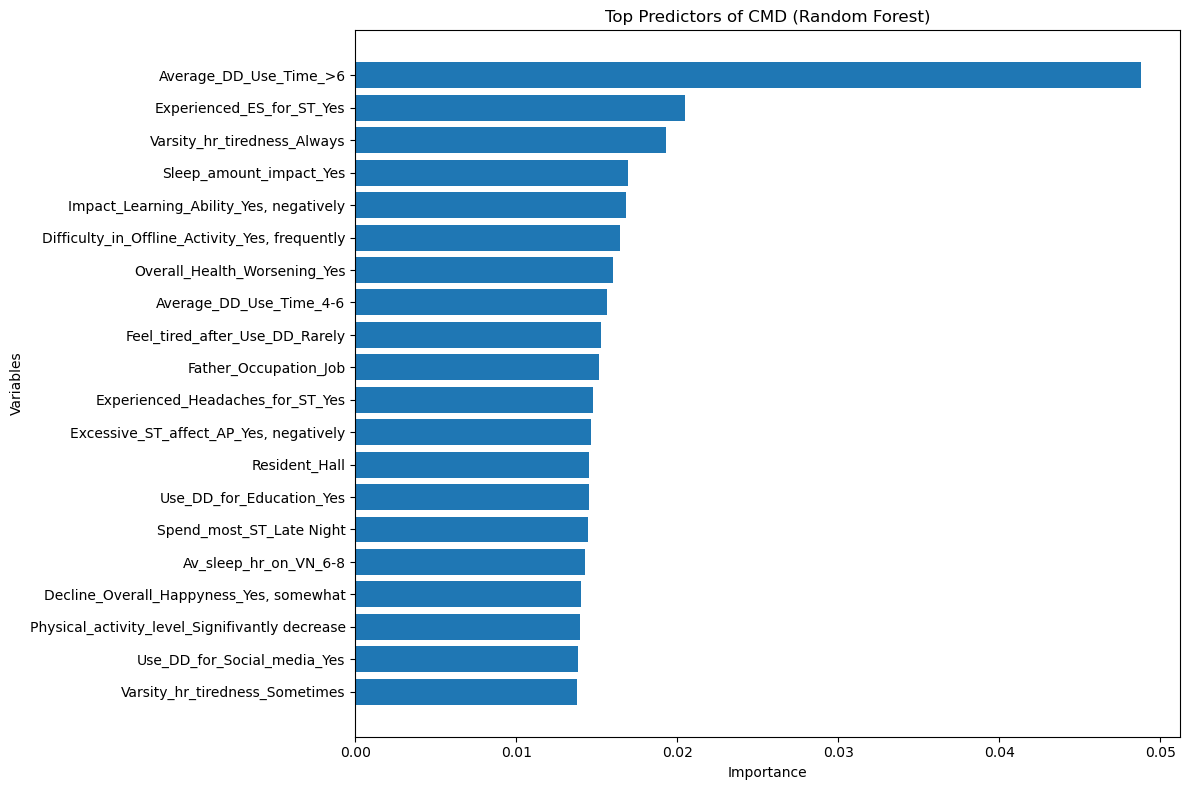


Variable importance saved successfully.

Predictions saved successfully.


In [1]:
# =========================================================
# RANDOM FOREST ANALYSIS FOR CMD PREDICTION
# =========================================================
# This script:
# 1. Loads SPSS dataset
# 2. Uses almost all variables
# 3. Removes CMD-related leakage variables
# 4. Encodes categorical predictors
# 5. Trains Random Forest model
# 6. Evaluates prediction performance
# 7. Shows top CMD predictors
# 8. Plots variable importance
# =========================================================


# =========================================================
# 1. IMPORT LIBRARIES
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)


# =========================================================
# 2. LOAD SPSS DATASET
# =========================================================

# Use your actual SPSS file path

df = pd.read_spss(
    r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\SPSS\Data Entry_Finallll_2_48.sav'
)


# =========================================================
# 3. CHECK DATASET
# =========================================================

print("\n===== FIRST 5 ROWS =====")
print(df.head())

print("\n===== COLUMN NAMES =====")
print(df.columns)

print("\n===== DATA INFO =====")
print(df.info())


# =========================================================
# 4. DEFINE TARGET VARIABLE
# =========================================================

TARGET = 'CMD'


# =========================================================
# 5. REMOVE VARIABLES THAT CAUSE DATA LEAKAGE
# =========================================================
# IMPORTANT:
# These variables were used to CREATE CMD
# so they should NOT be predictors.

exclude_vars = [

    # Outcome variables
    'CMD',
    'CMD_Severity',

    # DASS-derived variables
    'Depression',
    'Anxiety',
    'Stress',
    'D_Score',
    'A_Score',
    'S_Score',

    # DASS individual items
    'DASS21_d1',
    'DASS21_d2',
    'DASS21_d3',
    'DASS21_d4',
    'DASS21_d5',
    'DASS21_d6',
    'DASS21_d7',

    'DASS21_a1',
    'DASS21_a2',
    'DASS21_a3',
    'DASS21_a4',
    'DASS21_a5',
    'DASS21_a6',
    'DASS21_a7',

    'DASS21_s1',
    'DASS21_s2',
    'DASS21_s3',
    'DASS21_s4',
    'DASS21_s5',
    'DASS21_s6',
    'DASS21_s7'
]


# =========================================================
# 6. CREATE PREDICTOR LIST
# =========================================================

predictors = [

    col for col in df.columns
    if col not in exclude_vars
]


print("\n===== NUMBER OF PREDICTORS =====")
print(len(predictors))


# =========================================================
# 7. CREATE ANALYSIS DATASET
# =========================================================

analysis_df = df[predictors + [TARGET]].copy()


# =========================================================
# 8. HANDLE MISSING VALUES
# =========================================================

analysis_df = analysis_df.dropna()

print("\n===== DATASET SHAPE AFTER DROPPING MISSING =====")
print(analysis_df.shape)


# =========================================================
# 9. DEFINE X AND y
# =========================================================

X = analysis_df[predictors]
y = analysis_df[TARGET]


# =========================================================
# 10. CONVERT TARGET VARIABLE TO NUMERIC
# =========================================================
# ONLY IF NEEDED

print("\n===== TARGET UNIQUE VALUES =====")
print(y.unique())


# Example:
# If values are:
# 'No CMD' and 'CMD Present'

if y.dtype == 'object':

    y = y.map({
        'No CMD': 0,
        'CMD Present': 1
    })


# =========================================================
# 11. ENCODE CATEGORICAL VARIABLES
# =========================================================

X = pd.get_dummies(
    X,
    drop_first=True
)

print("\n===== ENCODED DATA SHAPE =====")
print(X.shape)


# =========================================================
# 12. TRAIN-TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.30,
    random_state=42,
    stratify=y
)


print("\n===== TRAINING DATA =====")
print(X_train.shape)

print("\n===== TESTING DATA =====")
print(X_test.shape)


# =========================================================
# 13. TRAIN RANDOM FOREST MODEL
# =========================================================

rf = RandomForestClassifier(

    n_estimators=300,
    random_state=42,

    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2
)

rf.fit(X_train, y_train)


# =========================================================
# 14. PREDICT CMD
# =========================================================

y_pred = rf.predict(X_test)


# =========================================================
# 15. MODEL PERFORMANCE
# =========================================================

print("\n==============================")
print("MODEL PERFORMANCE")
print("==============================")

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# =========================================================
# 16. VARIABLE IMPORTANCE
# =========================================================

importance_df = pd.DataFrame({

    'Variable': X.columns,
    'Importance': rf.feature_importances_
})


importance_df = importance_df.sort_values(

    by='Importance',
    ascending=False
)


print("\n==============================")
print("TOP PREDICTORS OF CMD")
print("==============================")

print(importance_df.head(20))


# =========================================================
# 17. PLOT TOP 20 PREDICTORS
# =========================================================

top20 = importance_df.head(20)

plt.figure(figsize=(12,8))

plt.barh(
    top20['Variable'],
    top20['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Variables')

plt.title(
    'Top Predictors of CMD (Random Forest)'
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()


# =========================================================
# 18. SAVE VARIABLE IMPORTANCE
# =========================================================

importance_df.to_csv(

    'CMD_variable_importance.csv',
    index=False
)

print("\nVariable importance saved successfully.")


# =========================================================
# 19. OPTIONAL: SAVE PREDICTIONS
# =========================================================

predictions_df = pd.DataFrame({

    'Actual_CMD': y_test,
    'Predicted_CMD': y_pred
})

predictions_df.to_csv(

    'CMD_predictions.csv',
    index=False
)

print("\nPredictions saved successfully.")

In [2]:
print(importance_df.head(30))

                                           Variable  Importance
47                           Average_DD_Use_Time_>6    0.048785
65                        Experienced_ES_for_ST_Yes    0.020499
101                     Varsity_hr_tiredness_Always    0.019327
93                          Sleep_amount_impact_Yes    0.016938
82          Impact_Learning_Ability_Yes, negatively    0.016836
80   Difficulty_in_Offline_Activity_Yes, frequently    0.016467
84                     Overall_Health_Worsening_Yes    0.015983
45                          Average_DD_Use_Time_4-6    0.015654
63                   Feel_tired_after_Use_DD_Rarely    0.015238
23                            Father_Occupation_Job    0.015135
66                 Experienced_Headaches_for_ST_Yes    0.014782
60           Excessive_ST_affect_AP_Yes, negatively    0.014620
13                                    Resident_Hall    0.014522
48                         Use_DD_for_Education_Yes    0.014490
55                         Spend_most_ST

In [4]:
top_vars = importance_df.head(25)['Variable'].tolist()

X_selected = X[top_vars]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(

    X_selected,
    y,

    test_size=0.30,
    random_state=42,
    stratify=y
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print(accuracy_score(y_test, y_pred))

0.6095238095238096


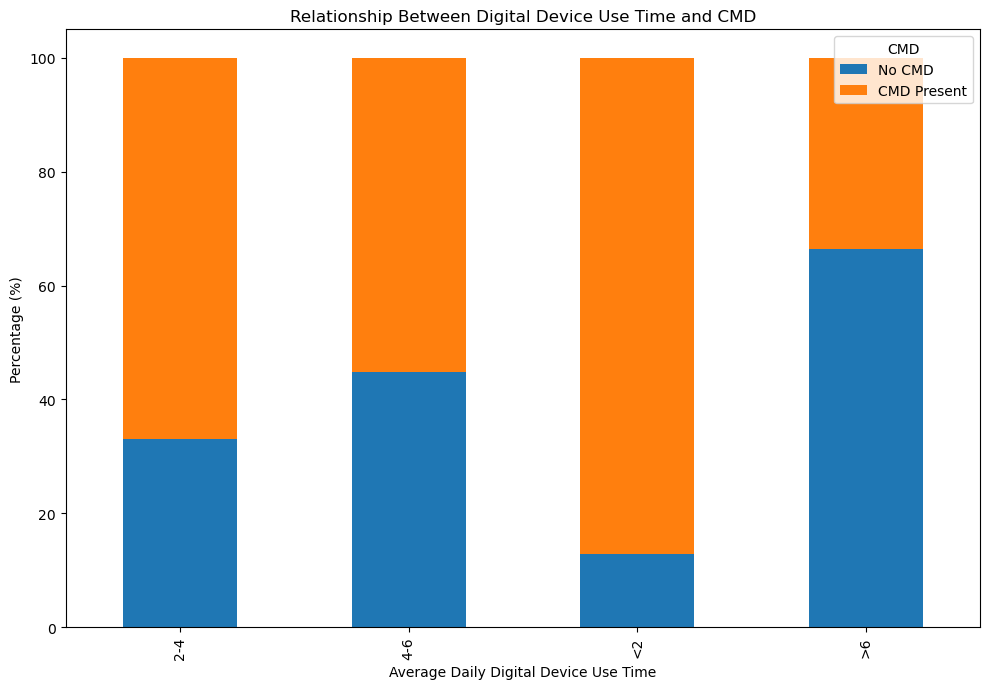

In [6]:
import matplotlib.pyplot as plt

# ============================================
# CMD percentage by DD use
# ============================================

cmd_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100


# ============================================
# Plot
# ============================================

cmd_table.plot(

    kind='bar',
    stacked=True,
    figsize=(10,7)
)

plt.xlabel('Average Daily Digital Device Use Time')
plt.ylabel('Percentage (%)')

plt.title(
    'Relationship Between Digital Device Use Time and CMD'
)

plt.legend(

    title='CMD',
    labels=['No CMD', 'CMD Present']
)

plt.tight_layout()

plt.show()

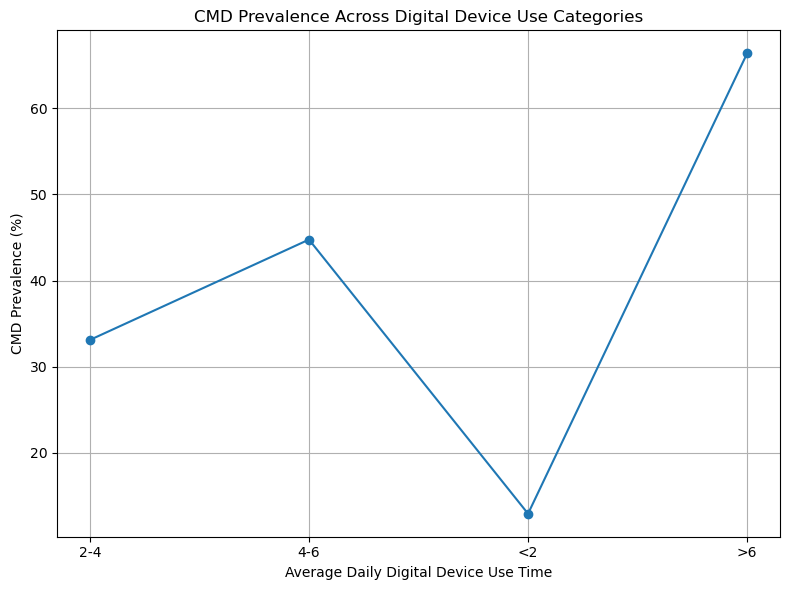

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================
# Calculate CMD prevalence
# ============================================

cmd_prev = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100


# CMD prevalence only

cmd_prev = cmd_prev['CMD Present']


# ============================================
# Plot
# ============================================

plt.figure(figsize=(8,6))

plt.plot(

    cmd_prev.index,
    cmd_prev.values,

    marker='o'
)

plt.xlabel('Average Daily Digital Device Use Time')
plt.ylabel('CMD Prevalence (%)')

plt.title(
    'CMD Prevalence Across Digital Device Use Categories'
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [11]:
print(cmd_table.columns)

Index([], dtype='object', name='CMD')


In [13]:
print(df['Average_DD_Use_Time'].unique())

[NaN]
Categories (4, object): ['<2 hr' < '2–4 hr' < '4-6 hr' < '>6 hr']


In [14]:
print(df['CMD'].unique())

['CMD Present' 'No CMD']



RESULTS WILL BE SAVED IN:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results

Feature importance table saved.
Top 15 predictors saved.
Model performance saved.
Classification report saved.
Confusion matrix table saved.


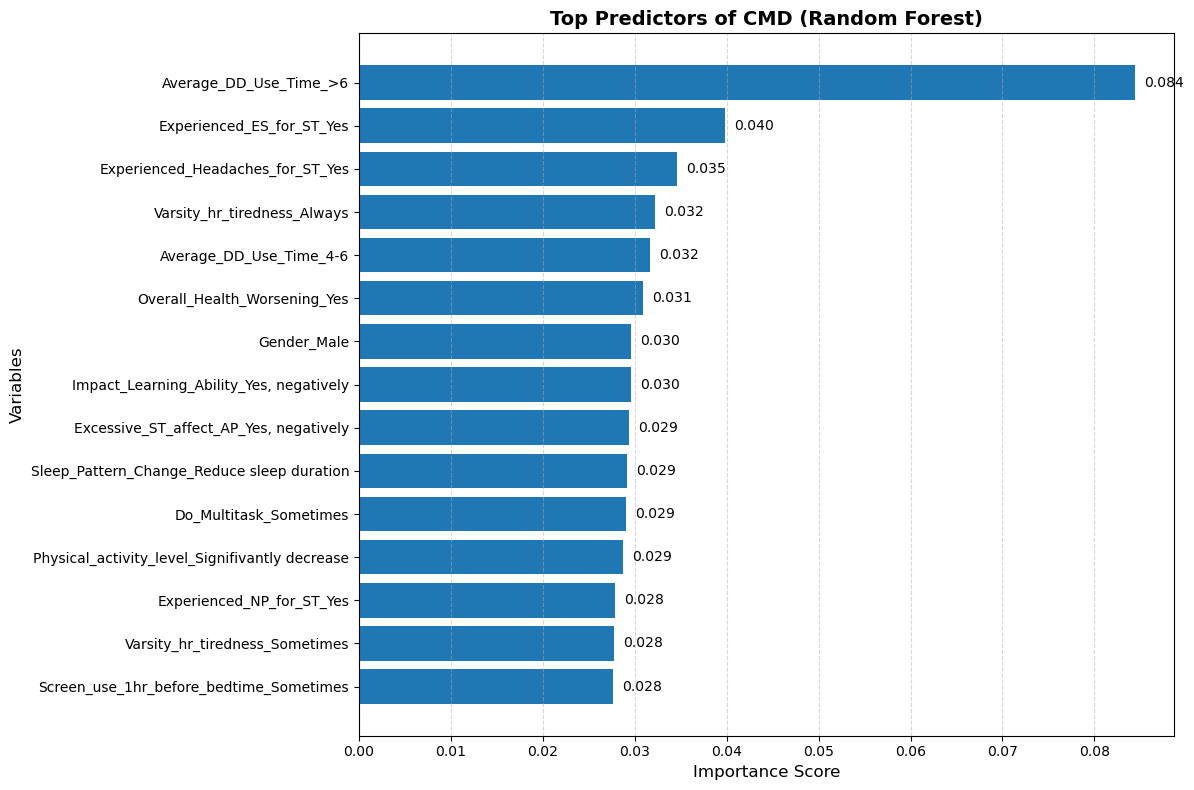

Feature importance figure exported.


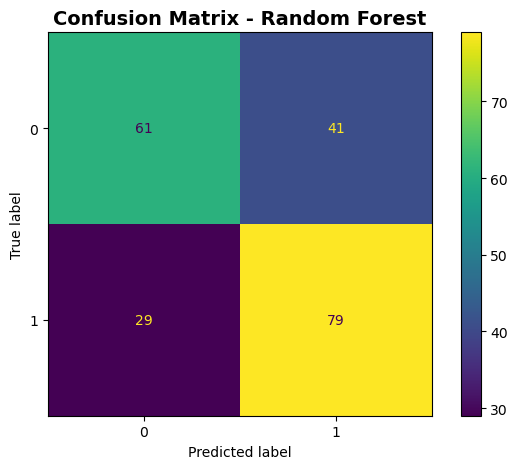

Confusion matrix figure exported.

ALL RANDOM FOREST RESULTS EXPORTED SUCCESSFULLY


EXPORTED RANDOM FOREST FILES

CSV FILES:
1. RF_CMD_Feature_Importance.csv
2. RF_Top15_CMD_Predictors.csv
3. RF_Model_Performance.csv
4. RF_Classification_Report.csv
5. RF_Confusion_Matrix.csv

EXCEL FILE:
6. RF_CMD_Full_Results.xlsx

FIGURES:
7. RF_Top15_CMD_Predictors.png
8. RF_Confusion_Matrix.png

SAVE LOCATION

G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results


In [23]:
# =========================================================
# EXPORT RANDOM FOREST RESULTS + FIGURES
# PUBLICATION-QUALITY OUTPUTS
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (

    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =========================================================
# 1. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nRESULTS WILL BE SAVED IN:")

print(OUTPUT_DIR)


# =========================================================
# 2. SAVE FEATURE IMPORTANCE TABLE
# =========================================================

importance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'RF_CMD_Feature_Importance.csv'
    ),

    index=False
)

print("\nFeature importance table saved.")


# =========================================================
# 3. SAVE TOP 15 PREDICTORS
# =========================================================

top15 = importance_df.head(15)

top15.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'RF_Top15_CMD_Predictors.csv'
    ),

    index=False
)

print("Top 15 predictors saved.")


# =========================================================
# 4. SAVE MODEL PERFORMANCE
# =========================================================

performance_df = pd.DataFrame({

    'Metric': [

        'Accuracy'
    ],

    'Value': [

        accuracy
    ]
})

performance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'RF_Model_Performance.csv'
    ),

    index=False
)

print("Model performance saved.")


# =========================================================
# 5. SAVE CLASSIFICATION REPORT
# =========================================================

report_dict = classification_report(

    y_test,
    y_pred,

    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'RF_Classification_Report.csv'
    )
)

print("Classification report saved.")


# =========================================================
# 6. SAVE CONFUSION MATRIX TABLE
# =========================================================

cm = confusion_matrix(

    y_test,
    y_pred
)

cm_df = pd.DataFrame(

    cm,

    columns=[

        'Predicted_No_CMD',
        'Predicted_CMD'
    ],

    index=[

        'Actual_No_CMD',
        'Actual_CMD'
    ]
)

cm_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'RF_Confusion_Matrix.csv'
    )
)

print("Confusion matrix table saved.")


# =========================================================
# 7. EXPORT FEATURE IMPORTANCE FIGURE
# =========================================================

plt.figure(figsize=(12,8))

plt.barh(

    top15['Variable'],
    top15['Importance']
)


# Add importance labels

for index, value in enumerate(top15['Importance']):

    plt.text(

        value + 0.001,
        index,

        f'{value:.3f}',

        va='center',
        fontsize=10
    )


plt.xlabel(

    'Importance Score',
    fontsize=12
)

plt.ylabel(

    'Variables',
    fontsize=12
)

plt.title(

    'Top Predictors of CMD (Random Forest)',

    fontsize=14,
    fontweight='bold'
)

plt.gca().invert_yaxis()

plt.grid(

    axis='x',
    linestyle='--',
    alpha=0.5
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'RF_Top15_CMD_Predictors.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Feature importance figure exported.")


# =========================================================
# 8. EXPORT CONFUSION MATRIX FIGURE
# =========================================================

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm
)

disp.plot()

plt.title(

    'Confusion Matrix - Random Forest',

    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'RF_Confusion_Matrix.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix figure exported.")


# =========================================================
# 9. SAVE ALL RESULTS INTO EXCEL
# =========================================================

excel_path = os.path.join(

    OUTPUT_DIR,

    'RF_CMD_Full_Results.xlsx'
)

with pd.ExcelWriter(excel_path) as writer:

    importance_df.to_excel(

        writer,
        sheet_name='Feature_Importance',
        index=False
    )

    top15.to_excel(

        writer,
        sheet_name='Top15_Predictors',
        index=False
    )

    performance_df.to_excel(

        writer,
        sheet_name='Model_Performance',
        index=False
    )

    report_df.to_excel(

        writer,
        sheet_name='Classification_Report'
    )

    cm_df.to_excel(

        writer,
        sheet_name='Confusion_Matrix'
    )

print("\nALL RANDOM FOREST RESULTS EXPORTED SUCCESSFULLY")


# =========================================================
# 10. FINAL OUTPUT SUMMARY
# =========================================================

print("""

===================================
EXPORTED RANDOM FOREST FILES
===================================

CSV FILES:
1. RF_CMD_Feature_Importance.csv
2. RF_Top15_CMD_Predictors.csv
3. RF_Model_Performance.csv
4. RF_Classification_Report.csv
5. RF_Confusion_Matrix.csv

EXCEL FILE:
6. RF_CMD_Full_Results.xlsx

FIGURES:
7. RF_Top15_CMD_Predictors.png
8. RF_Confusion_Matrix.png

===================================
SAVE LOCATION
===================================

""" + OUTPUT_DIR)